In [117]:
import numpy as np
import pandas as pd

In [118]:
df = pd.read_csv('../experiments/full_pipeline/final_data.csv')
df = df[~df['fish'].str.contains('ctrl', na=False)]



In [119]:
def unedited_end(barcode):
    return barcode.endswith('NONE_NONE_NONE_NONE_NONE_NONE')

# Unedited

In [122]:
unedited = 'NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE'
df.query('barcode == @unedited')['fish'].nunique()

21

In [124]:
df['fish'].nunique()

24

In [131]:
unique_pairs.query('edit1 == "NONE_NONE_NONE_NONE"')['fish'].nunique()

21

In [132]:
unique_pairs.query('edit2 == "NONE_NONE_NONE_NONE_NONE_NONE"')['fish'].nunique()

24

In [133]:
# It would also be informative to ask whether the number of detected
# edited barcode species is negatively correlated with the abundance
# of the unedited barcode

In [138]:
df.head()

,barcode,fish,sample,replicate,file,reads,proportion
0,12D+34_12D+60_NONE_NONE_3D+143_84D+169_84D+169...,fish1,1,1,fish1_s1_rep1,57559,0.750512
1,12D+34_12D+60_NONE_NONE_NONE_NONE_54D+199_54D+...,fish1,1,1,fish1_s1_rep1,643,0.008384
2,1D+38_28D+41_NONE_18D+113_NONE_NONE_54D+199_54...,fish1,1,1,fish1_s1_rep1,1345,0.017537
3,1D+38_28D+41_NONE_NONE_NONE_NONE_54D+199_54D+1...,fish1,1,1,fish1_s1_rep1,10646,0.138813
4,1D+38_28D+41_NONE_NONE_NONE_NONE_NONE_NONE_NON...,fish1,1,1,fish1_s1_rep1,792,0.010327


In [148]:
total_reads = df.groupby("fish")["reads"].sum()

unedited_reads = (
    df[df["barcode"] == unedited]
    .groupby("fish")["reads"]
    .sum()
)

unique_barcodes = (
    df.groupby("fish")["barcode"]
    .nunique()
)

result = pd.DataFrame({
    "abundance": unedited_reads.div(total_reads),
    "unique_barcodes": unique_barcodes
}).fillna({"abundance": 0}).reset_index()

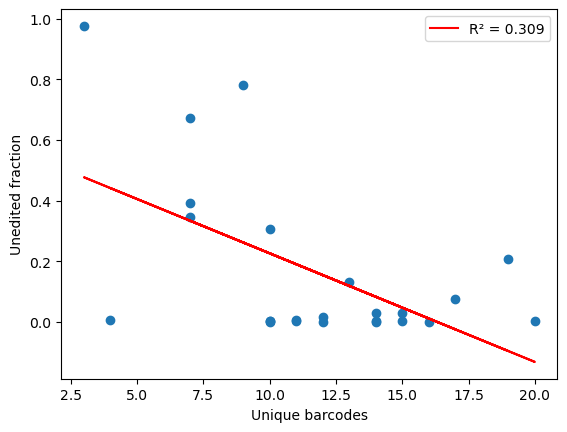

Slope: -0.03582
Intercept: 0.5842
R²: 0.3087
P-value: 4.8200e-03


In [149]:
from scipy.stats import linregress
import matplotlib.pyplot as plt
import numpy as np

x = result["unique_barcodes"]
y = result["abundance"]

# fit linear model
slope, intercept, r_value, p_value, std_err = linregress(x, y)

# R²
r2 = r_value**2

# plot
plt.scatter(x, y)
plt.plot(x, intercept + slope * x, color="red",
         label=f"R² = {r2:.3f}")

plt.xlabel("Unique barcodes")
plt.ylabel("Unedited fraction")
plt.legend()
plt.show()

print(f"Slope: {slope:.4g}")
print(f"Intercept: {intercept:.4g}")
print(f"R²: {r2:.4f}")
print(f"P-value: {p_value:.4e}")

In [155]:
len(result.query('abundance < 0.01'))

12

(array([16.,  1.,  1.,  2.,  1.,  0.,  1.,  0.,  1.,  1.]),
 array([0.        , 0.09757676, 0.19515351, 0.29273027, 0.39030703,
        0.48788378, 0.58546054, 0.6830373 , 0.78061405, 0.87819081,
        0.97576757]),
 <BarContainer object of 10 artists>)

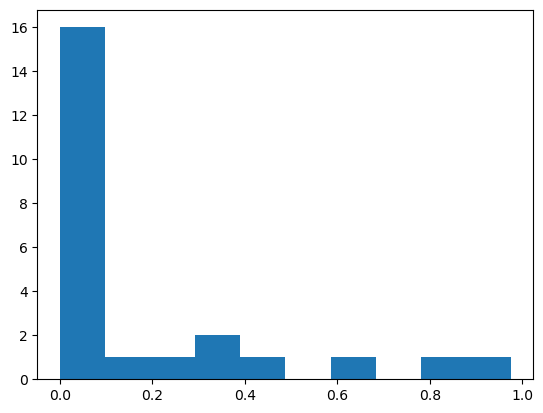

In [150]:
plt.hist(result['abundance'])

# Homoplasy

In [108]:
EMPTY_EDIT2 = "NONE_NONE_NONE_NONE_NONE_NONE"
H_EDITED = 36 / 737
H_EMPTY = 224 / 1582

df = unique_pairs.drop_duplicates(["fish", "edit1", "edit2"])

lineage_estimates = (
    df.assign(empty=df["edit2"].eq(EMPTY_EDIT2))
      .groupby("fish")["empty"]
      .agg(observed_empty="sum", observed_total="size")
)

lineage_estimates["observed_edited"] = (
    lineage_estimates["observed_total"] - lineage_estimates["observed_empty"]
)
lineage_estimates["estimated_lineages"] = (
    lineage_estimates["observed_edited"] / (1 - H_EDITED)
    + lineage_estimates["observed_empty"] / (1 - H_EMPTY)
)
lineage_estimates["estimated_lost"] = (
    lineage_estimates["estimated_lineages"]
    - lineage_estimates["observed_total"]
)

display(lineage_estimates)
print("Observed total:", lineage_estimates["observed_total"].sum())
print("Estimated total:", lineage_estimates["estimated_lineages"].sum())

,observed_empty,observed_total,observed_edited,estimated_lineages,estimated_lost
fish,,,,,
fish1,2,12,10,12.843449,0.843449
fish10,1,3,2,3.267659,0.267659
fish12,1,15,14,15.883921,0.883921
fish13,3,14,11,15.059753,1.059753
fish14,4,20,16,21.481477,1.481477
fish15,1,12,11,12.729856,0.729856
fish16,3,15,12,16.111108,1.111108
fish17,8,17,9,18.781784,1.781784
fish18,1,7,6,7.473080,0.473080


Observed total: 280
Estimated total: 304.6028501257408


In [109]:
import numpy as np
import pandas as pd
from scipy.optimize import least_squares

EMPTY_EDIT2 = "NONE_NONE_NONE_NONE_NONE_NONE"
S2_EDITED = 36 / 737
S3_EDITED = 9 / 1865

df = unique_pairs.drop_duplicates(["fish", "edit1", "edit2"])

groups = (
    df.assign(empty=df["edit2"].eq(EMPTY_EDIT2))
      .groupby(["fish", "edit1"])
      .agg(K=("edit2", "size"), has_empty=("empty", "max"))
)

observed_empty = groups["has_empty"].sum()
observed_edited = (groups["K"] - groups["has_empty"]).sum()
K = groups["K"].to_numpy()

def choose2(x):
    return x * (x - 1) / 2

def choose3(x):
    return x * (x - 1) * (x - 2) / 6

def predictions(r, p0):
    M = r * K
    expected_empty = np.sum(1 - (1 - p0)**M)
    expected_edited = np.sum(
        M * (1 - p0)
        - choose2(M) * (1 - p0)**2 * S2_EDITED
        + choose3(M) * (1 - p0)**3 * S3_EDITED
    )
    return expected_empty, expected_edited

def residuals(theta):
    r, p0 = theta
    expected_empty, expected_edited = predictions(r, p0)
    return [
        (expected_empty - observed_empty) / np.sqrt(observed_empty),
        (expected_edited - observed_edited) / np.sqrt(observed_edited),
    ]

fit = least_squares(
    residuals,
    x0=[1.1, 0.35],
    bounds=([1, 0], [10, 1]),
)

r_hat, p0_hat = fit.x
groups["estimated_lineages"] = r_hat * groups["K"]

print({
    "observed_barcodes": int(groups["K"].sum()),
    "observed_empty_barcodes": int(observed_empty),
    "observed_edited_barcodes": int(observed_edited),
    "undercount_multiplier": r_hat,
    "estimated_unedited_probability": p0_hat,
    "estimated_lineages": groups["estimated_lineages"].sum(),
    "estimated_lost": groups["estimated_lineages"].sum() - groups["K"].sum(),
    "fit_residuals": residuals(fit.x),
})

{'observed_barcodes': 280, 'observed_empty_barcodes': 90, 'observed_edited_barcodes': 190, 'undercount_multiplier': np.float64(1.0650800773800257), 'estimated_unedited_probability': np.float64(0.35290059950561986), 'estimated_lineages': np.float64(298.2224216664073), 'estimated_lost': np.float64(18.222421666407286), 'fit_residuals': [np.float64(4.4938668397781774e-15), np.float64(1.0309637589642928e-14)]}


In [126]:
unique_pairs = df[['barcode', 'fish']].drop_duplicates()
unique_pairs

,barcode,fish
0,12D+34_12D+60_NONE_NONE_3D+143_84D+169_84D+169...,fish1
1,12D+34_12D+60_NONE_NONE_NONE_NONE_54D+199_54D+...,fish1
2,1D+38_28D+41_NONE_18D+113_NONE_NONE_54D+199_54...,fish1
3,1D+38_28D+41_NONE_NONE_NONE_NONE_54D+199_54D+1...,fish1
4,1D+38_28D+41_NONE_NONE_NONE_NONE_NONE_NONE_NON...,fish1
...,...,...
5170,3D+35_27D+51_50D+86_50D+86_NONE_NONE_NONE_NONE...,fish8
5171,3D+35_27D+51_NONE_NONE_NONE_NONE_54D+199_54D+1...,fish8
5172,3D+35_27D+51_NONE_NONE_NONE_NONE_NONE_NONE_NON...,fish8
5173,4I+37+ATGC_NONE_NONE_9D+115_NONE_NONE_NONE_NON...,fish8


In [127]:
splits = unique_pairs['barcode'].str.split('_', n=4, expand=True)

unique_pairs['edit1'] = splits.iloc[:, 0:4].agg('_'.join, axis=1)
unique_pairs['edit2'] = splits.iloc[:, 4]
unique_pairs

,barcode,fish,edit1,edit2
0,12D+34_12D+60_NONE_NONE_3D+143_84D+169_84D+169...,fish1,12D+34_12D+60_NONE_NONE,3D+143_84D+169_84D+169_84D+169_84D+169_NONE
1,12D+34_12D+60_NONE_NONE_NONE_NONE_54D+199_54D+...,fish1,12D+34_12D+60_NONE_NONE,NONE_NONE_54D+199_54D+199_54D+199_NONE
2,1D+38_28D+41_NONE_18D+113_NONE_NONE_54D+199_54...,fish1,1D+38_28D+41_NONE_18D+113,NONE_NONE_54D+199_54D+199_54D+199_NONE
3,1D+38_28D+41_NONE_NONE_NONE_NONE_54D+199_54D+1...,fish1,1D+38_28D+41_NONE_NONE,NONE_NONE_54D+199_54D+199_54D+199_NONE
4,1D+38_28D+41_NONE_NONE_NONE_NONE_NONE_NONE_NON...,fish1,1D+38_28D+41_NONE_NONE,NONE_NONE_NONE_NONE_NONE_NONE
...,...,...,...,...
5170,3D+35_27D+51_50D+86_50D+86_NONE_NONE_NONE_NONE...,fish8,3D+35_27D+51_50D+86_50D+86,NONE_NONE_NONE_NONE_NONE_NONE
5171,3D+35_27D+51_NONE_NONE_NONE_NONE_54D+199_54D+1...,fish8,3D+35_27D+51_NONE_NONE,NONE_NONE_54D+199_54D+199_54D+199_NONE
5172,3D+35_27D+51_NONE_NONE_NONE_NONE_NONE_NONE_NON...,fish8,3D+35_27D+51_NONE_NONE,NONE_NONE_NONE_NONE_NONE_NONE
5173,4I+37+ATGC_NONE_NONE_9D+115_NONE_NONE_NONE_NON...,fish8,4I+37+ATGC_NONE_NONE_9D+115,NONE_NONE_NONE_NONE_NONE_NONE


In [73]:
def count_unique_edits(s):
    parts = s.split('_')
    filtered = [p for p in parts if p != "NONE"]
    return len(set(filtered))



In [74]:
unique_pairs['n_second_edits'] = unique_pairs['edit2'].map(count_unique_edits)

In [75]:
unique_pairs.query('n_second_edits > 1')

,barcode,fish,edit1,edit2,n_second_edits
0,12D+34_12D+60_NONE_NONE_3D+143_84D+169_84D+169...,fish1,12D+34_12D+60_NONE_NONE,3D+143_84D+169_84D+169_84D+169_84D+169_NONE,2
5,7D+36_12D+60_NONE_1I+119+A&5D+121_19D+130_4S+1...,fish1,7D+36_12D+60_NONE_1I+119+A&5D+121,19D+130_4S+169+CAGA_6D+195_1D+222&1I+229+T_8D+...,5
21,12D+34_12D+60_NONE_NONE_3D+143_NONE_54D+199_54...,fish1,12D+34_12D+60_NONE_NONE,3D+143_NONE_54D+199_54D+199_54D+199_NONE,2
45,12D+34_12D+60_NONE_1I+119+A&5D+121_19D+130_4S+...,fish1,12D+34_12D+60_NONE_1I+119+A&5D+121,19D+130_4S+169+CAGA_6D+195_1D+222&1I+229+T_8D+...,5
95,1D+38_28D+41_NONE_NONE_NONE_6D+167_54D+199_54D...,fish1,1D+38_28D+41_NONE_NONE,NONE_6D+167_54D+199_54D+199_54D+199_NONE,2
...,...,...,...,...,...
4736,12D+34_1D+60&1I+66+A_1I+91+C&16I+94+GGCTGCACGG...,fish50,12D+34_1D+60&1I+66+A_1I+91+C&16I+94+GGCTGCACGG...,59D+141_59D+141_59D+141_NONE_3D+251_NONE,2
4737,12D+34_1D+60&1I+66+A_1I+91+C&8D+94_4S+114+GGCT...,fish50,12D+34_1D+60&1I+66+A_1I+91+C&8D+94_4S+114+GGCT,10D+135_9D+167_13D+197_13I+229+GACTCCATACAGT_2...,5
4738,12I+37+ATGGAGTCGAGC_12D+60_54D+90_54D+90_54D+9...,fish50,12I+37+ATGGAGTCGAGC_12D+60_54D+90_54D+90,54D+90_1D+173_NONE_NONE_5D+248_NONE,3
4740,12I+37+ATGGAGTCGAGC_12D+60_NONE_9D+115_NONE_2D...,fish50,12I+37+ATGGAGTCGAGC_12D+60_NONE_9D+115,NONE_2D+173_NONE_NONE_27D+241_NONE,2


In [50]:
homoplasy = []
n_second_edits = []

p = []

for bc in unique_pairs['edit2'].unique():
    # print(bc)
    h = len(unique_pairs.query('edit2 == @bc')[['fish', 'edit1']].drop_duplicates())
    if h > 1:
        homoplasy.append(h)
        c = count_unique_edits(bc)
        n_second_edits.append(c)
        if c > 1:
            p.append(bc)

In [51]:
p

['19D+130_4S+169+CAGA_6D+195_1D+222&1I+229+T_8D+244_NONE',
 '8D+146_9D+167_13D+197_13I+228+CGACTCCATACTG_8I+254+CTCCATAC_NONE',
 '1D+145_82D+173_82D+173_82D+173_82D+173_NONE',
 '55D+146_55D+146_55D+146_NONE_2D+248_NONE',
 '14D+132_9D+164_55D+199_55D+199_55D+199_NONE',
 'NONE_3D+172_NONE_NONE_12D+242_NONE',
 'NONE_6D+167_NONE_NONE_1I+254+C_NONE']

In [67]:
unique_pairs.query('edit2 == @p[3]')

,barcode,fish,edit1,edit2,n_second_edits
1377,3D+35_12D+60_NONE_NONE_55D+146_55D+146_55D+146...,fish16,3D+35_12D+60_NONE_NONE,55D+146_55D+146_55D+146_NONE_2D+248_NONE,2
1401,11I+38+TGGAGTATCAT_5S+60+CACAT_NONE_NONE_55D+1...,fish16,11I+38+TGGAGTATCAT_5S+60+CACAT_NONE_NONE,55D+146_55D+146_55D+146_NONE_2D+248_NONE,2
1407,29I+36+GGAGTCGATGCAGTATCATTCGGACAGCA_12D+60_NO...,fish16,29I+36+GGAGTCGATGCAGTATCATTCGGACAGCA_12D+60_NO...,55D+146_55D+146_55D+146_NONE_2D+248_NONE,2
1439,11I+38+TGGAGTATCAT_12D+60_NONE_NONE_55D+146_55...,fish16,11I+38+TGGAGTATCAT_12D+60_NONE_NONE,55D+146_55D+146_55D+146_NONE_2D+248_NONE,2


In [68]:
list(unique_pairs.query('edit2 == @p[3]')['barcode'])

['3D+35_12D+60_NONE_NONE_55D+146_55D+146_55D+146_NONE_2D+248_NONE',
 '11I+38+TGGAGTATCAT_5S+60+CACAT_NONE_NONE_55D+146_55D+146_55D+146_NONE_2D+248_NONE',
 '29I+36+GGAGTCGATGCAGTATCATTCGGACAGCA_12D+60_NONE_NONE_55D+146_55D+146_55D+146_NONE_2D+248_NONE',
 '11I+38+TGGAGTATCAT_12D+60_NONE_NONE_55D+146_55D+146_55D+146_NONE_2D+248_NONE']

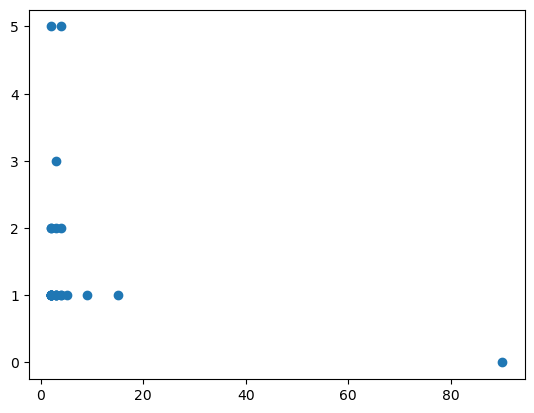

In [47]:
import matplotlib.pyplot as plt
plt.scatter(homoplasy, n_second_edits)

In [49]:
np.mean(n_second_edits)

np.float64(1.4814814814814814)

(array([ 1.,  0., 19.,  0.,  4.,  0.,  1.,  0.,  0.,  2.]),
 array([0. , 0.5, 1. , 1.5, 2. , 2.5, 3. , 3.5, 4. , 4.5, 5. ]),
 <BarContainer object of 10 artists>)

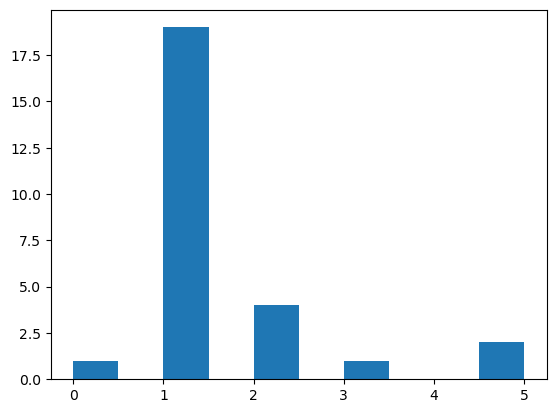

In [48]:
plt.hist(n_second_edits)

In [91]:
EMPTY_EDIT1 = "NONE_NONE_NONE_NONE"
EMPTY_EDIT2 = "NONE_NONE_NONE_NONE_NONE_NONE"
choose2 = lambda x: x * (x - 1) // 2

# Edit1 recurrence across fish
for edit in ['edit1', 'edit2']:
    edit_fish_counts = unique_pairs.groupby(edit)["fish"].nunique().sort_values(ascending=False)
    repeated_edit = edit_fish_counts[edit_fish_counts > 1]
    
    print(f"{edit} RECURRENCE")
    print("Distinct edit values:", unique_pairs[edit].nunique())
    print("Edit1 values appearing in >1 fish (ignoring NONE):", len(repeated_edit) - 1)
    print("Fraction recurring (ignoring NONE):", (len(repeated_edit) - 1) / (unique_pairs[edit].nunique() - 1))
    display(repeated_edit.rename("number_of_fish").to_frame())

edit1 RECURRENCE
Distinct edit values: 176
Edit1 values appearing in >1 fish (ignoring NONE): 6
Fraction recurring (ignoring NONE): 0.03428571428571429


,number_of_fish
edit1,
NONE_NONE_NONE_NONE,21
1D+38_NONE_NONE_NONE,3
54D+36_54D+36_54D+36_NONE,3
NONE_54D+65_54D+65_54D+65,2
7D+33_NONE_NONE_NONE,2
5D+34_NONE_NONE_NONE,2
107D+38_107D+38_107D+38_107D+38,2


edit2 RECURRENCE
Distinct edit values: 128
Edit1 values appearing in >1 fish (ignoring NONE): 15
Fraction recurring (ignoring NONE): 0.11811023622047244


,number_of_fish
edit2,
NONE_NONE_NONE_NONE_NONE_NONE,24
NONE_81D+170_81D+170_81D+170_81D+170_NONE,12
NONE_NONE_54D+199_54D+199_54D+199_NONE,6
54D+119_54D+119_NONE_NONE_NONE_NONE,3
81D+61_NONE_NONE_NONE_NONE_NONE,3
1D+145_NONE_NONE_NONE_NONE_NONE,3
NONE_87D+167_87D+167_87D+167_87D+167_NONE,3
NONE_6D+167_NONE_NONE_NONE_NONE,3
108D+142_108D+142_108D+142_108D+142_108D+142_NONE,3


In [110]:
EMPTY_EDIT2 = "NONE_NONE_NONE_NONE_NONE_NONE"
choose2 = lambda n: n * (n - 1) // 2

df = unique_pairs.drop_duplicates(["fish", "edit1", "edit2"])

# Eligible within-fish pairs with different edit1 values
eligible_all = (
    choose2(df.groupby("fish").size()).sum()
    - choose2(df.groupby(["fish", "edit1"]).size()).sum()
)

# Empty-empty pairs
empty = df[df["edit2"] == EMPTY_EDIT2]
empty_pairs = (
    choose2(empty.groupby("fish").size()).sum()
    - choose2(empty.groupby(["fish", "edit1"]).size()).sum()
)
phi_U = empty_pairs / eligible_all

# Matching nonempty-edit pairs, conditional on both being edited
edited = df[df["edit2"] != EMPTY_EDIT2]
eligible_edited = (
    choose2(edited.groupby("fish").size()).sum()
    - choose2(edited.groupby(["fish", "edit1"]).size()).sum()
)
matching_edited = (
    choose2(edited.groupby(["fish", "edit2"]).size()).sum()
    - choose2(edited.groupby(["fish", "edit1", "edit2"]).size()).sum()
)
phi_E = matching_edited / eligible_edited

print({
    "phi_E": phi_E,
    "phi_U": phi_U,
    "edited_matching_pairs": int(matching_edited),
    "edited_eligible_pairs": int(eligible_edited),
    "unedited_matching_pairs": int(empty_pairs),
    "all_eligible_pairs": int(eligible_all),
})

{'phi_E': np.float64(0.048846675712347354), 'phi_U': np.float64(0.1415929203539823), 'edited_matching_pairs': 36, 'edited_eligible_pairs': 737, 'unedited_matching_pairs': 224, 'all_eligible_pairs': 1582}


In [115]:
import numpy as np
from scipy.optimize import brentq

EMPTY_EDIT2 = "NONE_NONE_NONE_NONE_NONE_NONE"

phi_U = 224 / 1582
phi_E_conditional = 36 / 737
p_both_edited = 737 / 1582
phi_E_joint = phi_E_conditional * p_both_edited  # equivalent to 36 / 1582
phi_total = phi_U + phi_E_joint                  # equivalent to 260 / 1582

df = unique_pairs.drop_duplicates(["fish", "edit1", "edit2"])

groups = (
    df.groupby(["fish", "edit1"])
    .size()
    .rename("K")
    .reset_index()
)

K = groups["K"].to_numpy(dtype=float)
observed_total = K.sum()

def equation(r):
    L = r * K
    expected_observed = np.sum(
        L - phi_total * L * (L - 1) / 2
    )
    return expected_observed - observed_total

grid = np.linspace(1 + 1e-8, 10, 10000)
i = next(
    (i for i in range(len(grid) - 1)
     if equation(grid[i]) * equation(grid[i + 1]) <= 0),
    None,
)

if i is None:
    raise ValueError("No usable correction-factor root found.")

r_hat = brentq(equation, grid[i], grid[i + 1])
groups["L_hat"] = r_hat * groups["K"]

fish_estimates = (
    groups.groupby("fish")
    .agg(observed_barcodes=("K", "sum"), estimated_lineages=("L_hat", "sum"))
)
fish_estimates["estimated_hidden"] = (
    fish_estimates["estimated_lineages"]
    - fish_estimates["observed_barcodes"]
)

pair_opportunities = np.sum(
    groups["L_hat"] * (groups["L_hat"] - 1) / 2
)
estimated_hidden_edited = phi_E_joint * pair_opportunities
estimated_hidden_unedited = phi_U * pair_opportunities

print({
    "phi_E_conditional": phi_E_conditional,
    "phi_E_joint": phi_E_joint,
    "phi_U": phi_U,
    "phi_total": phi_total,
    "correction_factor": r_hat,
    "observed_total": observed_total,
    "estimated_total": groups["L_hat"].sum(),
    "estimated_hidden_edited": estimated_hidden_edited,
    "estimated_hidden_unedited": estimated_hidden_unedited,
})
display(fish_estimates)

{'phi_E_conditional': 0.048846675712347354, 'phi_E_joint': 0.022756005056890013, 'phi_U': 0.1415929203539823, 'phi_total': 0.16434892541087232, 'correction_factor': 1.0980070007661717, 'observed_total': np.float64(280.0), 'estimated_total': np.float64(307.441960214528), 'estimated_hidden_edited': np.float64(3.7996560297038977), 'estimated_hidden_unedited': np.float64(23.64230418482425)}


,observed_barcodes,estimated_lineages,estimated_hidden
fish,,,
fish1,12,13.176084,1.176084
fish10,3,3.294021,0.294021
fish12,15,16.470105,1.470105
fish13,14,15.372098,1.372098
fish14,20,21.960140,1.960140
fish15,12,13.176084,1.176084
fish16,15,16.470105,1.470105
fish17,17,18.666119,1.666119
fish18,7,7.686049,0.686049


In [95]:
print(len(unique_pairs.query('edit1 == @EMPTY_EDIT1')['fish'].unique()))
print(len(unique_pairs.query('edit2 == @EMPTY_EDIT2')['fish'].unique()))

21
24


In [96]:
EMPTY_EDIT2 = "NONE_NONE_NONE_NONE_NONE_NONE"
PHI_EDITED = 0.048846675712347354

df = unique_pairs.drop_duplicates(["fish", "edit1", "edit2"])
edited = df[df["edit2"] != EMPTY_EDIT2]

K = edited.groupby(["fish", "edit1"]).size()
observed_edited = K.sum()
estimated_hidden_edited = PHI_EDITED * (K * (K - 1) / 2).sum()
estimated_edited_lineages = observed_edited + estimated_hidden_edited

empty_groups = (
    df[df["edit2"] == EMPTY_EDIT2][["fish", "edit1"]]
    .drop_duplicates()
    .shape[0]
)

lower_bound_total = estimated_edited_lineages + empty_groups

print({
    "observed_edited_barcodes": int(observed_edited),
    "estimated_hidden_edited": estimated_hidden_edited,
    "estimated_edited_lineages": estimated_edited_lineages,
    "observed_empty_groups": empty_groups,
    "total_lineage_lower_bound": lower_bound_total,
})

{'observed_edited_barcodes': 190, 'estimated_hidden_edited': np.float64(3.8100407055630936), 'estimated_edited_lineages': np.float64(193.8100407055631), 'observed_empty_groups': 90, 'total_lineage_lower_bound': np.float64(283.8100407055631)}


In [99]:
import pandas as pd

EMPTY_EDIT2 = "NONE_NONE_NONE_NONE_NONE_NONE"

df = unique_pairs.drop_duplicates(["fish", "edit1", "edit2"])

def distinct_group_triples(counts):
    """Number of triples drawn from three different edit1 groups."""
    n = counts.sum()
    return int((n**3 - 3*n*(counts**2).sum() + 2*(counts**3).sum()) // 6)

def estimate_S3(data):
    # Eligible triples: same fish, three different edit1 values
    eligible = sum(
        distinct_group_triples(g.groupby("edit1").size())
        for _, g in data.groupby("fish")
    )

    # Matching triples: eligible triples also sharing edit2
    matching = sum(
        distinct_group_triples(g.groupby("edit1").size())
        for _, g in data.groupby(["fish", "edit2"])
    )

    return {
        "matching_triples": matching,
        "eligible_triples": eligible,
        "S3_hat": matching / eligible if eligible else float("nan"),
    }

S3_including_empty = estimate_S3(df)
S3_excluding_empty = estimate_S3(
    df[df["edit2"] != EMPTY_EDIT2]
)

print("Including empty:", S3_including_empty)
print("Excluding empty:", S3_excluding_empty)

Including empty: {'matching_triples': 448, 'eligible_triples': 5931, 'S3_hat': 0.07553532287978418}
Excluding empty: {'matching_triples': 9, 'eligible_triples': 1865, 'S3_hat': 0.00482573726541555}


In [90]:
def edit2_homoplasy(data):
    # Between-fish pairs sharing edit2
    total_by_edit2 = data.groupby("edit2").size()
    fish_edit2 = data.groupby(["fish", "edit2"]).size()
    between_collisions = choose2(total_by_edit2).sum() - choose2(fish_edit2).sum()

    total_n = len(data)
    fish_n = data.groupby("fish").size()
    between_pairs = choose2(total_n) - choose2(fish_n).sum()

    # Within-fish pairs with different edit1 but shared edit2
    within_collisions = (
        choose2(fish_edit2).sum()
        - choose2(data.groupby(["fish", "edit1", "edit2"]).size()).sum()
    )
    within_pairs = (
        choose2(fish_n).sum()
        - choose2(data.groupby(["fish", "edit1"]).size()).sum()
    )

    # Number of distinct edit2 sequences involved
    between_types = (
        data.groupby("edit2")["fish"].nunique().gt(1).sum()
    )
    within_types = (
        data.groupby(["fish", "edit2"])["edit1"].nunique().gt(1)
        .groupby("edit2").any().sum()
    )

    return pd.Series({
        "between_fish_collisions": int(between_collisions),
        "between_fish_eligible_pairs": int(between_pairs),
        "between_fish_rate": between_collisions / between_pairs,
        "between_fish_edit2_types": int(between_types),
        "within_fish_collisions": int(within_collisions),
        "within_fish_eligible_pairs": int(within_pairs),
        "within_fish_rate": within_collisions / within_pairs,
        "within_fish_edit2_types": int(within_types),
    })

results = pd.DataFrame({
    "including_empty": edit2_homoplasy(df),
    "excluding_empty": edit2_homoplasy(df[df["edit2"] != EMPTY_EDIT2]),
})

print("\nEDIT2 HOMOPLASY")
display(results)


EDIT2 HOMOPLASY


,including_empty,excluding_empty
between_fish_collisions,3951.000000,170.000000
between_fish_eligible_pairs,37352.000000,17140.000000
between_fish_rate,0.105777,0.009918
between_fish_edit2_types,16.000000,15.000000
within_fish_collisions,260.000000,36.000000
within_fish_eligible_pairs,1582.000000,737.000000
within_fish_rate,0.164349,0.048847
within_fish_edit2_types,19.000000,18.000000


In [57]:
x = (
    df[df["edit2"] != EMPTY_EDIT2]
    .groupby(["fish", "edit2"])["edit1"].nunique()
    .rename("n_edit1")
    .reset_index()
)

within_by_fish = (
    x.assign(collisions=lambda d: d["n_edit1"] * (d["n_edit1"] - 1) // 2)
    .groupby("fish")
    .agg(
        collision_pairs=("collisions", "sum"),
        homoplastic_edit2_types=("collisions", lambda s: (s > 0).sum()),
    )
    .sort_values("collision_pairs", ascending=False)
)

within_by_edit2 = (
    x.groupby("edit2")
    .agg(
        collision_pairs=("n_edit1", lambda n: ((n * (n - 1)) // 2).sum()),
        fish_with_collision=("n_edit1", lambda n: (n > 1).sum()),
    )
    .query("collision_pairs > 0")
    .sort_values("collision_pairs", ascending=False)
)

display(within_by_fish)
display(within_by_edit2)

,collision_pairs,homoplastic_edit2_types
fish,,
fish16,6,1
fish1,4,2
fish42,4,2
fish44,3,3
fish40,3,1
fish35,3,1
fish12,3,1
fish14,3,3
fish5,2,2


,collision_pairs,fish_with_collision
edit2,,
55D+146_55D+146_55D+146_NONE_2D+248_NONE,6,1
NONE_NONE_54D+199_54D+199_54D+199_NONE,4,2
14D+132_9D+164_55D+199_55D+199_55D+199_NONE,3,1
NONE_87D+167_87D+167_87D+167_87D+167_NONE,3,1
8D+146_9D+167_13D+197_13I+228+CGACTCCATACTG_8I+254+CTCCATAC_NONE,3,1
NONE_3D+172_NONE_NONE_12D+242_NONE,3,1
NONE_81D+170_81D+170_81D+170_81D+170_NONE,3,3
NONE_NONE_NONE_NONE_1D+254_NONE,1,1
NONE_NONE_NONE_NONE_10D+243_NONE,1,1


In [58]:
edited = df[df["edit2"] != EMPTY_EDIT2]

def fish_stats(d):
    n = len(d)
    eligible = n * (n - 1) // 2
    eligible -= sum(len(x) * (len(x) - 1) // 2 for _, x in d.groupby("edit1"))

    n_by_edit2 = d.groupby("edit2").size()
    n_by_both = d.groupby(["edit1", "edit2"]).size()
    collisions = (
        (n_by_edit2 * (n_by_edit2 - 1) // 2).sum()
        - (n_by_both * (n_by_both - 1) // 2).sum()
    )

    return pd.Series({
        "barcodes": n,
        "eligible_pairs": eligible,
        "collision_pairs": collisions,
        "phi_hat": collisions / eligible if eligible else float("nan"),
    })

fish_phi = edited.groupby("fish").apply(fish_stats, include_groups=False)
display(fish_phi.sort_values("phi_hat", ascending=False))

,barcodes,eligible_pairs,collision_pairs,phi_hat
fish,,,,
fish42,8.0,23.0,4.0,0.173913
fish44,8.0,22.0,3.0,0.136364
fish1,10.0,39.0,4.0,0.102564
fish51,5.0,10.0,1.0,0.100000
fish16,12.0,66.0,6.0,0.090909
fish18,6.0,13.0,1.0,0.076923
fish5,8.0,28.0,2.0,0.071429
fish40,10.0,43.0,3.0,0.069767
fish35,10.0,45.0,3.0,0.066667


In [27]:
unique_pairs['edit2']

0       3D+143_84D+169_84D+169_84D+169_84D+169_NONE
1            NONE_NONE_54D+199_54D+199_54D+199_NONE
2            NONE_NONE_54D+199_54D+199_54D+199_NONE
3            NONE_NONE_54D+199_54D+199_54D+199_NONE
4                     NONE_NONE_NONE_NONE_NONE_NONE
                           ...                     
5170                  NONE_NONE_NONE_NONE_NONE_NONE
5171         NONE_NONE_54D+199_54D+199_54D+199_NONE
5172                  NONE_NONE_NONE_NONE_NONE_NONE
5173                  NONE_NONE_NONE_NONE_NONE_NONE
5214                  NONE_NONE_NONE_NONE_NONE_NONE
Name: edit2, Length: 280, dtype: str

In [21]:
choose2 = lambda x: x * (x - 1) // 2

# Eligible pairs: same fish, different edit1
n_fish = unique_pairs.groupby("fish").size()
n_fish_edit1 = unique_pairs.groupby(["fish", "edit1"]).size()
denominator = choose2(n_fish).sum() - choose2(n_fish_edit1).sum()

# Colliding pairs: eligible pairs that also share edit2
n_fish_edit2 = unique_pairs.groupby(["fish", "edit2"]).size()
n_full = unique_pairs.groupby(["fish", "edit1", "edit2"]).size()
numerator = choose2(n_fish_edit2).sum() - choose2(n_full).sum()

phi_hat = numerator / denominator if denominator else float("nan")

print({"colliding_pairs": numerator, "eligible_pairs": denominator, "phi_hat": phi_hat})

{'colliding_pairs': np.int64(260), 'eligible_pairs': np.int64(1582), 'phi_hat': np.float64(0.16434892541087232)}


In [22]:
import pandas as pd

EMPTY_EDIT2 = "NONE_NONE_NONE_NONE_NONE_NONE"
choose2 = lambda x: x * (x - 1) // 2

def estimate_phi(data, exclude_empty=False):
    df = data.drop_duplicates(["fish", "edit1", "edit2"])
    if exclude_empty:
        df = df[df["edit2"].ne(EMPTY_EDIT2)]

    denominator = (
        choose2(df.groupby("fish").size()).sum()
        - choose2(df.groupby(["fish", "edit1"]).size()).sum()
    )
    numerator = (
        choose2(df.groupby(["fish", "edit2"]).size()).sum()
        - choose2(df.groupby(["fish", "edit1", "edit2"]).size()).sum()
    )

    return {
        "colliding_pairs": int(numerator),
        "eligible_pairs": int(denominator),
        "phi_hat": numerator / denominator if denominator else float("nan"),
    }

phi_all = estimate_phi(unique_pairs)
phi_edited = estimate_phi(unique_pairs, exclude_empty=True)

print("Including empty edit2:", phi_all)
print("Excluding empty edit2:", phi_edited)

Including empty edit2: {'colliding_pairs': 260, 'eligible_pairs': 1582, 'phi_hat': np.float64(0.16434892541087232)}
Excluding empty edit2: {'colliding_pairs': 36, 'eligible_pairs': 737, 'phi_hat': np.float64(0.048846675712347354)}


In [26]:
import numpy as np

EMPTY_EDIT2 = "NONE_NONE_NONE_NONE_NONE_NONE"

def estimate_total_lineages(data, phi, exclude_empty=False):
    df = data.drop_duplicates(["fish", "edit1", "edit2"])
    if exclude_empty:
        df = df[df["edit2"].ne(EMPTY_EDIT2)]

    K = df.groupby(["fish", "edit1"]).size()
    M_eff = 1 / phi

    if (K >= M_eff).any():
        bad = K[K >= M_eff]
        raise ValueError(
            f"{len(bad)} groups have K >= 1/phi ({M_eff:.2f}); "
            "the equal-probability approximation cannot estimate them."
        )

    L_hat = np.log1p(-K / M_eff) / np.log1p(-1 / M_eff)
    by_group = K.rename("observed_barcodes").to_frame()
    by_group["estimated_lineages"] = L_hat

    return {
        "observed_barcodes": int(K.sum()),
        "first_edit_groups": len(K),
        "effective_edit_states": M_eff,
        "estimated_lineages": float(L_hat.sum()),
        "estimated_hidden_lineages": float((L_hat - K).sum()),
        "by_group": by_group,
    }

with_empty = estimate_total_lineages(
    unique_pairs, phi=0.16434892541087232
)

without_empty = estimate_total_lineages(
    unique_pairs,
    phi=0.048846675712347354,
    exclude_empty=True,
)

for label, result in [
    ("Including empty edit2", with_empty),
    ("Excluding empty edit2", without_empty),
]:
    print(f"\n{label}")
    for key, value in result.items():
        if key != "by_group":
            print(f"{key}: {value}")

# Optional group-level results:
# display(with_empty["by_group"])
# display(without_empty["by_group"])

ValueError: 1 groups have K >= 1/phi (6.08); the equal-probability approximation cannot estimate them.

In [24]:
import numpy as np
from scipy.optimize import brentq

EMPTY_EDIT2 = "NONE_NONE_NONE_NONE_NONE_NONE"

def estimate_total_lineages(data, exclude_empty=False):
    df = data.drop_duplicates(["fish", "edit1", "edit2"])
    if exclude_empty:
        df = df[df["edit2"].ne(EMPTY_EDIT2)]

    # Approximate shared second-edit probabilities from all fish.
    p = df["edit2"].value_counts(normalize=True).to_numpy()
    K = df.groupby(["fish", "edit1"]).size()

    def estimate_L(k):
        expected_K = lambda L: np.sum(1 - (1 - p) ** L)
        if k >= len(p):
            return np.inf

        upper = max(2 * k, 2)
        while expected_K(upper) < k and upper < 1e7:
            upper *= 2

        return brentq(lambda L: expected_K(L) - k, k, upper)

    L_hat = K.apply(estimate_L)
    by_group = K.rename("observed_barcodes").to_frame()
    by_group["estimated_lineages"] = L_hat

    return {
        "observed_barcodes": int(K.sum()),
        "first_edit_groups": len(K),
        "estimated_lineages": float(L_hat.sum()),
        "estimated_hidden_lineages": float((L_hat - K).sum()),
        "implied_phi": float(np.sum(p**2)),
        "by_group": by_group,
    }

with_empty = estimate_total_lineages(unique_pairs)
without_empty = estimate_total_lineages(unique_pairs, exclude_empty=True)

for label, result in [("Including empty", with_empty), ("Excluding empty", without_empty)]:
    print(f"\n{label}")
    for key, value in result.items():
        if key != "by_group":
            print(f"{key}: {value}")

ValueError: f(a) and f(b) must have different signs